### Exercise 1

Make an artificial DNA sequence of **200 to 600 bases** in length, in which to simulate **3 to 4 transposable elements**.
Implement a software application which can detect the positions of these transposable elements (**start**, **end**)
within the created DNA sequence.

**Note:** Intersect 2 or 3 transposons to see how the algorithm behaves in these situations.

#### What a transposon looks like in the DNA

A (DNA) transposon is a segment that can cut itself out and jump to another place in the genome. Two features make it recognisable:

- **Terminal inverted repeats (TIR)** - the two ends of the transposon are the *reverse complement* of each other
  (e.g. `ATGCAGGCTA ... TAGCCTGCAT`). The transposase enzyme recognises these ends.
- **Target site duplication (TSD)** - the transposase makes a *staggered cut* in the host DNA. After the transposon is
  inserted, the gaps are filled in, so the few bases of the target site are now found **on both sides** of the transposon
  (direct repeats).

```
                 ///|------------ TRANSPOSON ------------|///
                    \________ inverted repeats _________/

  Step 1 - host DNA, staggered cut at the target site ATGCA

        5' ...TAC ATGCA CAG... 3'
        3' ...ATG TACGT GTC... 5'

  Step 2 - insertion, gaps still to be filled

        5' ...TAC ATGCA [///|---- TRANSPOSON ----|///]       CAG... 3'
        3' ...ATG       [///|---- TRANSPOSON ----|///] TACGT GTC... 5'

  Step 3 - gaps filled, the target site is now duplicated

        5' ...TAC ATGCA [///|---- TRANSPOSON ----|///] ATGCA CAG... 3'
        3' ...ATG TACGT [///|---- TRANSPOSON ----|///] TACGT GTC... 5'
                \___/                                  \___/
                          direct repeats (TSD)
```

#### Building the artificial sequence

We start from a random host sequence of 260 bases and insert 4 transposons into it, exactly as in the diagram above
(staggered cut of 5 bases -> TSD on both sides). Each transposon is `IR + random body + reverse_complement(IR)`,
with an IR of 10 bases. Two of the transposons belong to the same *family* (same IR), as it happens in real genomes.

To get **intersecting transposons**, the last two insertions land inside an element that is already there
(a *nested* insertion):

| Element | Family | Length | Inserted into |
|:-:|:-:|:-:|:--|
| TE1 | A | 60 bp | host DNA |
| TE2 | B | 80 bp | host DNA |
| TE3 | A | 65 bp | the body of TE2 |
| TE4 | C | 50 bp | the body of TE3 (so TE2 > TE3 > TE4 intersect) |

Every insertion shifts the coordinates of what lies after it, so the program keeps the **true** start and end of every
element up to date; at the end these are compared with what the detector finds.

In [9]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import HTML, display

COMPLEMENT = str.maketrans("ACGT", "TGCA")
IR_LEN = 10      # length of the terminal inverted repeats
TSD_LEN = 5      # length of the target site (duplicated at insertion)


def reverse_complement(s):
    return s.translate(COMPLEMENT)[::-1]


def random_dna(n, rng):
    return "".join(rng.choice("ACGT") for _ in range(n))


def make_transposon(name, ir, body_len, rng):
    """A transposon = IR + random body + reverse complement of the IR (terminal inverted repeats)."""
    return {"name": name, "ir": ir, "seq": ir + random_dna(body_len, rng) + reverse_complement(ir)}


def insert(dna, elements, te, pos, tsd_len=TSD_LEN):
    """Insert te with a staggered cut at dna[pos:pos+tsd_len]; the target site ends up on both sides (TSD).
    The coordinates of the elements already in the sequence are shifted. Returns the new sequence."""
    q = pos + tsd_len                     # the transposon starts right after the first copy of the target site
    target = dna[pos:q]
    added = te["seq"] + target            # new = dna[:pos] + TSD + TE + TSD + dna[q:]
    for e in elements:
        # an insertion that splits the IR or the TSD of an element damages its signature
        if e["start"] - e["tsd_len"] < q < e["start"] + len(e["ir"]) or e["end"] - len(e["ir"]) < q < e["end"] + e["tsd_len"]:
            e["damaged"] = True
        if e["start"] >= q:
            e["start"] += len(added)
        if e["end"] > q:
            e["end"] += len(added)
    elements.append({**te, "start": q, "end": q + len(te["seq"]), "tsd": target, "tsd_len": tsd_len, "damaged": False})
    return dna[:q] + added + dna[q:]


rng = random.Random(6)
family = {f: random_dna(IR_LEN, rng) for f in "ABC"}
te1 = make_transposon("TE1", family["A"], 40, rng)
te2 = make_transposon("TE2", family["B"], 60, rng)
te3 = make_transposon("TE3", family["A"], 45, rng)
te4 = make_transposon("TE4", family["C"], 30, rng)

dna, truth = random_dna(260, rng), []
dna = insert(dna, truth, te2, 160)                       # into the host DNA
dna = insert(dna, truth, te1, 40)                        # into the host DNA, left of TE2
dna = insert(dna, truth, te3, truth[0]["start"] + 25)    # into the body of TE2
dna = insert(dna, truth, te4, truth[2]["start"] + 20)    # into the body of TE3
truth.sort(key=lambda e: e["start"])

assert 200 <= len(dna) <= 600
print(f"Artificial sequence: {len(dna)} bases\n")
print("Families (left IR ... right IR):")
for f, ir in family.items():
    print(f"  {f}: {ir} ... {reverse_complement(ir)}")
print(f"\n{'Element':<7} | {'Family':^6} | {'Start':>5} | {'End':>5} | {'Length':>6} | TSD")
print("-" * 46)
for e in truth:
    f = next(k for k, v in family.items() if v == e["ir"])
    print(f"{e['name']:<7} | {f:^6} | {e['start'] + 1:>5} | {e['end']:>5} | {e['end'] - e['start']:>6} | {e['tsd']}")

Artificial sequence: 535 bases

Families (left IR ... right IR):
  A: ATGAACTGGA ... TCCAGTTCAT
  B: GTCTACGATG ... CATCGTAGAC
  C: AGTGTACGAA ... TTCGTACACT

Element | Family | Start |   End | Length | TSD
----------------------------------------------
TE1     |   A    |    46 |   105 |     60 | AACTC
TE2     |   B    |   231 |   435 |    205 | CGGCC
TE3     |   A    |   261 |   380 |    120 | CAAAG
TE4     |   C    |   286 |   335 |     50 | CCGCA


The sequence, coloured by the transposon each base belongs to (for nested elements the innermost one wins).
The **inverted repeats** are bold and underlined and the **target site duplications** are boxed. Positions are 1-based.

In [10]:
COLORS = {"TE1": "#2a78d6", "TE2": "#eb6834", "TE3": "#1baf7a", "TE4": "#eda100"}


def show_sequence(dna, elements, width=60):
    """Render the sequence as HTML: background = innermost element, bold/underline = IR, box = TSD."""
    style, ir_bases, tsd_bases = [None] * len(dna), set(), set()
    for e in sorted(elements, key=lambda e: e["start"] - e["end"]):     # longest first, innermost painted last
        for i in range(e["start"], e["end"]):
            style[i] = COLORS[e["name"]]
        ir_bases |= set(range(e["start"], e["start"] + len(e["ir"]))) | set(range(e["end"] - len(e["ir"]), e["end"]))
        tsd_bases |= set(range(e["start"] - e["tsd_len"], e["start"])) | set(range(e["end"], e["end"] + e["tsd_len"]))
    rows = []
    for r in range(0, len(dna), width):
        css = []
        for i in range(r, min(r + width, len(dna))):
            parts = []
            if style[i]:
                parts.append(f"background:{style[i]}40")
            if i in ir_bases:
                parts.append("font-weight:700;text-decoration:underline")
            if i in tsd_bases:
                parts.append("box-shadow:inset 0 0 0 1px #52514e;border-radius:2px")
            css.append(";".join(parts))
        # join neighbouring bases with the same style into one span, so a TSD gets one box, not one per letter
        out, i = [], r
        while i < min(r + width, len(dna)):
            j = i
            while j < min(r + width, len(dna)) and css[j - r] == css[i - r]:
                j += 1
            out.append(f"<span style='{css[i - r]}'>{dna[i:j]}</span>")
            i = j
        rows.append(f"<span style='color:#8a8984'>{r + 1:>4}</span>  " + "".join(out))
    legend = "  ".join(f"<span style='background:{c}40;padding:0 6px'>{n}</span>" for n, c in COLORS.items() if any(e['name'] == n for e in elements))
    display(HTML(
        "<div style='background:#fcfcfb;color:#0b0b0b;padding:12px 14px;border-radius:6px;"
        "font-family:Menlo,Consolas,monospace;font-size:13px;line-height:1.7;white-space:pre'>"
        + legend + "   <b><u>IR</u></b>   <span style='box-shadow:inset 0 0 0 1px #52514e;border-radius:2px;padding:0 3px'>TSD</span>\n\n" + "\n".join(rows) + "</div>"))


show_sequence(dna, truth)

#### Detection algorithm

The detector does **not** know the families, the lengths or the number of transposons - it only uses the two signatures
of a transposon:

1. **Find inverted repeat pairs.** Every k-mer of length 8 (the minimum IR length) is stored in a dictionary with the
   positions where it occurs. For every position $i$ we look up the reverse complement of `dna[i:i+8]`; every hit at
   position $p$ gives a candidate element from $i$ to $j = p + 8$ (at least 30 bases long). The IR is then extended
   inwards for as long as the two ends stay complementary.
2. **Check the target site duplication.** A real insertion has the same 4-10 bases just *before* the start and just
   *after* the end: `dna[i-t:i] == dna[j:j+t]`. Pairs without a TSD are rejected - this removes almost all the IR pairs
   that appear by chance and also the pairs made of the ends of **two different elements of the same family**
   (e.g. the left IR of TE1 with the right IR of TE3), because two insertions practically never have the same target site.
3. **Remove duplicates.** A 10-base IR also contains shifted 8-base matches; candidates whose ends are closer than 8 bases
   to a better candidate (longer IR, then longer TSD) are dropped.
4. **Find intersections.** Element B is *nested* in A if it lies entirely inside A; if they only share a part, they *overlap*.

The search for pairs is fast because of the dictionary: $O(n)$ look-ups instead of comparing every pair of positions.

In [11]:
IR_MIN, TSD_MIN, TSD_MAX, LEN_MIN = 8, 4, 10, 30


def find_transposons(dna, ir_min=IR_MIN, tsd_min=TSD_MIN, tsd_max=TSD_MAX, len_min=LEN_MIN):
    """Return (elements, stats); each element = dict(start, end, ir, tsd) with 0-based, end-exclusive coordinates."""
    n = len(dna)
    kmers = defaultdict(list)
    for p in range(n - ir_min + 1):
        kmers[dna[p:p + ir_min]].append(p)

    candidates, ir_pairs = [], 0
    for i in range(n - ir_min + 1):
        for p in kmers.get(reverse_complement(dna[i:i + ir_min]), []):
            j = p + ir_min                                        # candidate element = dna[i:j]
            if j - i < len_min:
                continue
            ir_pairs += 1
            ir = ir_min                                           # extend the inverted repeat inwards
            while i + ir < j - ir - 1 and dna[i + ir] == reverse_complement(dna[j - ir - 1]):
                ir += 1
            tsd = next((t for t in range(tsd_max, tsd_min - 1, -1)  # longest direct repeat around the element
                        if i - t >= 0 and j + t <= n and dna[i - t:i] == dna[j:j + t]), 0)
            if tsd:
                candidates.append({"start": i, "end": j, "ir": ir, "tsd": tsd})

    found = []
    for c in sorted(candidates, key=lambda c: (-c["ir"], -c["tsd"])):
        if all(abs(c["start"] - f["start"]) >= ir_min or abs(c["end"] - f["end"]) >= ir_min for f in found):
            found.append(c)
    found.sort(key=lambda c: (c["start"], -c["end"]))
    return found, {"ir_pairs": ir_pairs, "with_tsd": len(candidates), "elements": len(found)}


def relation(a, b):
    """How element b relates to element a: 'contains' (b is inside a), 'inside' (a is inside b), 'overlaps' or None."""
    if a["start"] <= b["start"] and b["end"] <= a["end"]:
        return "contains"
    if b["start"] <= a["start"] and a["end"] <= b["end"]:
        return "inside"
    if b["start"] < a["end"] and a["start"] < b["end"]:
        return "overlaps"
    return None


found, stats = find_transposons(dna)
print(f"Inverted repeat pairs (>= {IR_MIN} bases, element >= {LEN_MIN} bases): {stats['ir_pairs']}")
print(f"  ... of which have a target site duplication:       {stats['with_tsd']}")
print(f"  ... after removing duplicates -> transposons found:  {stats['elements']}")

Inverted repeat pairs (>= 8 bases, element >= 30 bases): 20
  ... of which have a target site duplication:       4
  ... after removing duplicates -> transposons found:  4


In [12]:
def report(dna, found, truth=None):
    """Print the detected elements, their intersections and (if known) the comparison with the true positions."""
    names = {}
    for f in found:
        match = next((t for t in truth or [] if (t["start"], t["end"]) == (f["start"], f["end"])), None)
        names[id(f)] = match["name"] if match else f"#{len(names) + 1}"
    print(f"{'Found':<5} | {'Start':>5} | {'End':>5} | {'Length':>6} | {'IR':>2} | {'TSD':<10} | {'Left IR':<12} | {'Intersection':<24}"
          + (" | True position" if truth else ""))
    print("-" * (96 + (25 if truth else 0)))
    for f in found:
        parents = [names[id(g)] for g in found if g is not f and relation(g, f) == "contains"]
        overlaps = [names[id(g)] for g in found if g is not f and relation(g, f) == "overlaps"]
        children = [names[id(g)] for g in found if g is not f and relation(f, g) == "contains"]
        inter = "; ".join(p for p in ["inside " + ", ".join(parents) if parents else "",
                                      "contains " + ", ".join(children) if children else "",
                                      "overlaps " + ", ".join(overlaps) if overlaps else ""] if p)
        line = (f"{names[id(f)]:<5} | {f['start'] + 1:>5} | {f['end']:>5} | {f['end'] - f['start']:>6} | {f['ir']:>2} | "
                f"{dna[f['start'] - f['tsd']:f['start']]:<10} | {dna[f['start']:f['start'] + f['ir']]:<12} | {inter or '-':<24}")
        if truth:
            t = next((t for t in truth if t["name"] == names[id(f)]), None)
            line += f" | {t['start'] + 1}-{t['end']}  correct" if t else " | false positive"
        print(line)
    if truth:
        missed = [t["name"] for t in truth if t["name"] not in names.values()]
        print(f"\nDetected correctly: {len(truth) - len(missed)} / {len(truth)}" + (f"   missed: {', '.join(missed)}" if missed else ""))
    return names


names = report(dna, found, truth)

Found | Start |   End | Length | IR | TSD        | Left IR      | Intersection             | True position
-------------------------------------------------------------------------------------------------------------------------
TE1   |    46 |   105 |     60 | 10 | AACTC      | ATGAACTGGA   | -                        | 46-105  correct
TE2   |   231 |   435 |    205 | 10 | CGGCC      | GTCTACGATG   | contains TE3, TE4        | 231-435  correct
TE3   |   261 |   380 |    120 | 10 | CAAAG      | ATGAACTGGA   | inside TE2; contains TE4 | 261-380  correct
TE4   |   286 |   335 |     50 | 10 | CCGCA      | AGTGTACGAA   | inside TE2, TE3          | 286-335  correct

Detected correctly: 4 / 4


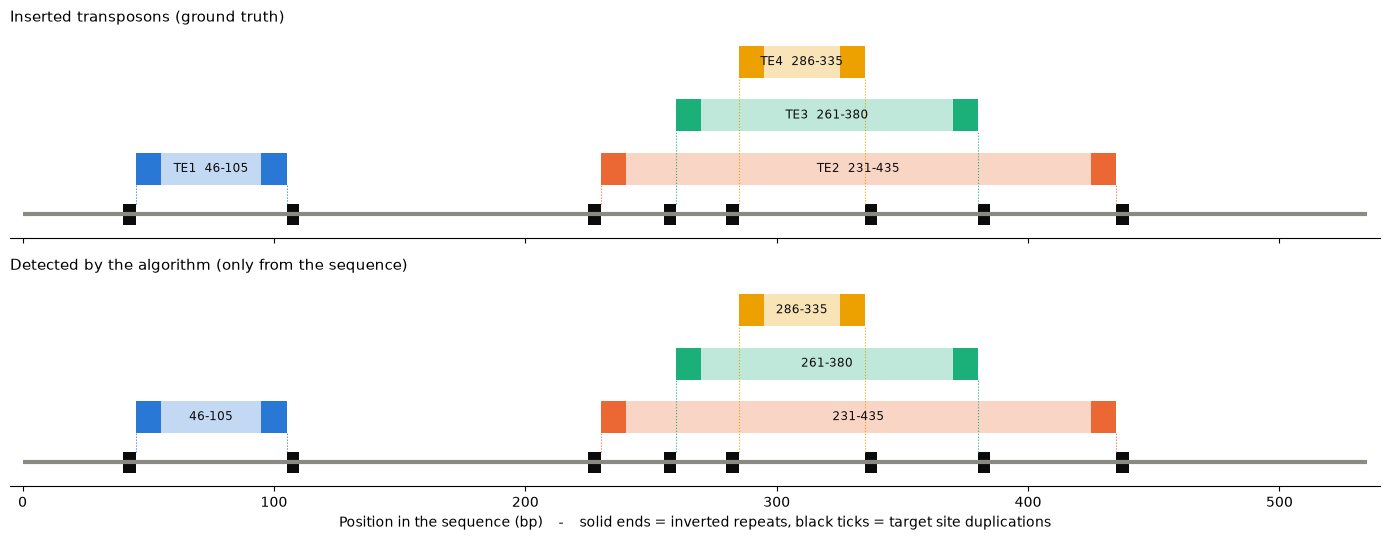

In [13]:
def levels(elements):
    """Give each element a row so that elements which intersect are drawn on different rows (nested = above)."""
    rows = []
    for e in sorted(elements, key=lambda e: (e["start"], -e["end"])):
        level = 0
        while any(r == level and o["start"] < e["end"] and e["start"] < o["end"] for o, r in rows):
            level += 1
        rows.append((e, level))
    return rows


def draw_map(ax, n, elements, title, colors, labels, ir_of, tsd_of):
    """Draw the sequence as a grey line and every element as a bar: IR = solid ends, body = light fill, TSD = ticks."""
    ax.plot([0, n], [-0.55, -0.55], color="#8a8984", lw=3, solid_capstyle="butt")
    for e, lvl in levels(elements):
        c, s, t, ir, tsd = colors(e), e["start"], e["end"], ir_of(e), tsd_of(e)
        ax.add_patch(plt.Rectangle((s, lvl), t - s, 0.6, color=c, alpha=0.28, lw=0))
        ax.add_patch(plt.Rectangle((s, lvl), ir, 0.6, color=c, lw=0))
        ax.add_patch(plt.Rectangle((t - ir, lvl), ir, 0.6, color=c, lw=0))
        for x in (s - tsd, t):
            ax.add_patch(plt.Rectangle((x, -0.75), tsd, 0.4, color="#0b0b0b", lw=0))
        ax.plot([s, s], [-0.35, lvl], color=c, lw=0.8, ls=":")
        ax.plot([t, t], [-0.35, lvl], color=c, lw=0.8, ls=":")
        ax.text((s + t) / 2, lvl + 0.3, labels(e), ha="center", va="center", fontsize=8.5, color="#0b0b0b")
    top = max([lvl for _, lvl in levels(elements)] + [0])
    ax.set_xlim(-5, n + 5)
    ax.set_ylim(-1, top + 0.9)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_title(title, loc="left", fontsize=11)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
draw_map(ax1, len(dna), truth, "Inserted transposons (ground truth)",
         colors=lambda e: COLORS[e["name"]], labels=lambda e: f"{e['name']}  {e['start'] + 1}-{e['end']}",
         ir_of=lambda e: len(e["ir"]), tsd_of=lambda e: e["tsd_len"])
draw_map(ax2, len(dna), found, "Detected by the algorithm (only from the sequence)",
         colors=lambda e: COLORS.get(names[id(e)], "#8a8984"), labels=lambda e: f"{e['start'] + 1}-{e['end']}",
         ir_of=lambda e: e["ir"], tsd_of=lambda e: e["tsd"])
ax2.set_xlabel("Position in the sequence (bp)    -    solid ends = inverted repeats, black ticks = target site duplications")
plt.tight_layout()
plt.show()

#### Intersecting transposons

**Nested elements** (TE4 inside TE3 inside TE2) are found without any problem: an insertion in the *body* of a transposon
does not touch its inverted repeats or its TSD, so the outer element still has both signatures - it just becomes longer.
The detector reports the full span of the outer element and the containment shows which element is inside which.

An insertion can only produce nesting. To also see how the algorithm behaves when two transposons **partly overlap**
(A starts, B starts, A ends, B ends - e.g. after a recombination), we build a second artificial sequence by hand where the
right end of P lies inside Q:

```
host  TSDx [IR_P  ...  TSDy [IR_Q  ...  IR_P'] TSDx  ...  IR_Q'] TSDy  host
           |<------------ P ------------->|
                            |<-------------- Q -------------->|
```

Second artificial sequence: 205 bases

Found | Start |   End | Length | IR | TSD        | Left IR      | Intersection             | True position
-------------------------------------------------------------------------------------------------------------------------
P     |    46 |   125 |     80 | 11 | CCATG      | TTTCCTCATGA  | overlaps Q               | 46-125  correct
Q     |    81 |   160 |     80 | 11 | TCCGT      | CAATTCAAAAC  | overlaps P               | 81-160  correct

Detected correctly: 2 / 2


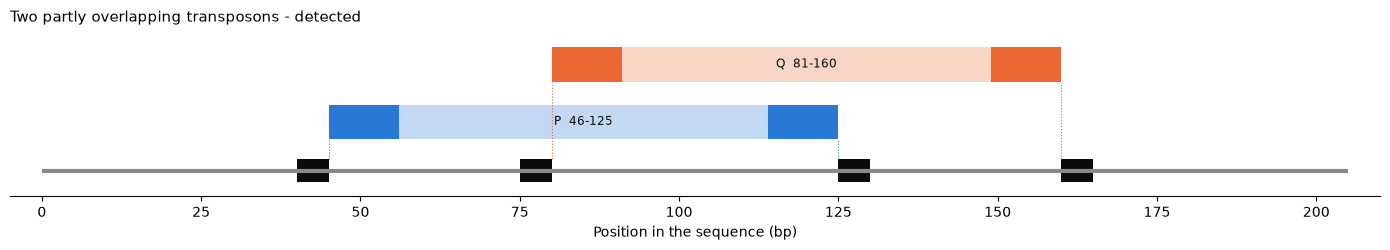

In [14]:
def build(parts):
    """Join (label, sequence) parts and return the sequence and the start position of every label."""
    seq, at = "", {}
    for label, s in parts:
        at.setdefault(label, []).append(len(seq))
        seq += s
    return seq, at


rng2 = random.Random(11)
ir_p, ir_q = random_dna(IR_LEN, rng2), random_dna(IR_LEN, rng2)
tsd_x, tsd_y = random_dna(TSD_LEN, rng2), random_dna(TSD_LEN, rng2)
dna2, at = build([
    ("host", random_dna(40, rng2)), ("tsd_x", tsd_x), ("P", ir_p), ("body", random_dna(20, rng2)),
    ("tsd_y", tsd_y), ("Q", ir_q), ("body", random_dna(25, rng2)), ("P_end", reverse_complement(ir_p)),
    ("tsd_x", tsd_x), ("body", random_dna(20, rng2)), ("Q_end", reverse_complement(ir_q)),
    ("tsd_y", tsd_y), ("host", random_dna(40, rng2)),
])
truth2 = [{"name": "P", "ir": ir_p, "start": at["P"][0], "end": at["P_end"][0] + IR_LEN, "tsd_len": TSD_LEN},
          {"name": "Q", "ir": ir_q, "start": at["Q"][0], "end": at["Q_end"][0] + IR_LEN, "tsd_len": TSD_LEN}]
COLORS.update({"P": COLORS["TE1"], "Q": COLORS["TE2"]})

print(f"Second artificial sequence: {len(dna2)} bases\n")
found2, stats2 = find_transposons(dna2)
names2 = report(dna2, found2, truth2)

fig, ax = plt.subplots(figsize=(14, 2.6))
draw_map(ax, len(dna2), found2, "Two partly overlapping transposons - detected",
         colors=lambda e: COLORS.get(names2[id(e)], "#8a8984"), labels=lambda e: f"{names2[id(e)]}  {e['start'] + 1}-{e['end']}",
         ir_of=lambda e: e["ir"], tsd_of=lambda e: e["tsd"])
ax.set_xlabel("Position in the sequence (bp)")
plt.tight_layout()
plt.show()

The detector pairs every IR with its reverse complement independently, so it does not assume that elements are
either separate or nested - the overlapping P and Q are both found with their exact positions.

#### When does the algorithm fail? A test on 1,000 random sequences

The case where the algorithm *can* fail is when a new transposon lands **inside the inverted repeat or the TSD** of an
element that is already there: its signature is split in two and that element can no longer be recognised by its ends.
To measure this, we generate 1,000 random sequences (host of 200-300 bases, 4 transposons with random IRs and lengths
inserted at **random** positions - so intersections happen by themselves) and compare the detections with the truth.

In [15]:
def random_case(rng, n_te=4):
    dna, elements = random_dna(rng.randint(200, 300), rng), []
    for k in range(n_te):
        te = make_transposon(f"TE{k + 1}", random_dna(IR_LEN, rng), rng.randint(30, 60), rng)
        dna = insert(dna, elements, te, rng.randint(0, len(dna) - TSD_LEN))
    return dna, elements


rng3 = random.Random(2026)
groups = defaultdict(lambda: [0, 0])          # group -> [elements, detected correctly]
false_pos = trials_with_nesting = 0
TRIALS = 1000
for _ in range(TRIALS):
    seq, elements = random_case(rng3)
    detected = {(f["start"], f["end"]) for f in find_transposons(seq)[0]}
    true_pos = {(e["start"], e["end"]) for e in elements}
    false_pos += len(detected - true_pos)
    trials_with_nesting += any(relation(a, b) for a in elements for b in elements if a is not b)
    for e in elements:
        if e["damaged"]:
            g = "IR or TSD split by a later insertion"
        elif any(relation(e, o) == "contains" for o in elements if o is not e):
            g = "contains other element(s)"
        elif any(relation(o, e) == "contains" for o in elements if o is not e):
            g = "nested inside another element"
        else:
            g = "alone (no intersection)"
        groups[g][0] += 1
        groups[g][1] += (e["start"], e["end"]) in detected

print(f"{TRIALS} random sequences, {4 * TRIALS} transposons, {trials_with_nesting} sequences with intersecting elements\n")
print(f"{'Situation of the transposon':<38} | {'Elements':>8} | {'Detected':>8} | {'Rate':>6}")
print("-" * 70)
order = ["alone (no intersection)", "nested inside another element", "contains other element(s)", "IR or TSD split by a later insertion"]
for g in order:
    total, ok = groups[g]
    print(f"{g:<38} | {total:>8} | {ok:>8} | {100 * ok / total:>5.1f}%")
total = sum(v[0] for v in groups.values())
ok = sum(v[1] for v in groups.values())
print("-" * 70)
print(f"{'all':<38} | {total:>8} | {ok:>8} | {100 * ok / total:>5.1f}%")
print(f"\nFalse positives: {false_pos} in {TRIALS} sequences")

1000 random sequences, 4000 transposons, 684 sequences with intersecting elements

Situation of the transposon            | Elements | Detected |   Rate
----------------------------------------------------------------------
alone (no intersection)                |     2209 |     2209 | 100.0%
nested inside another element          |      830 |      830 | 100.0%
contains other element(s)              |      592 |      591 |  99.8%
IR or TSD split by a later insertion   |      369 |      196 |  53.1%
----------------------------------------------------------------------
all                                    |     4000 |     3826 |  95.7%

False positives: 18 in 1000 sequences


### Conclusion

- The application finds the transposons only from the sequence, by looking for their two signatures: **terminal inverted
  repeats** (the two ends are reverse complements) and a **target site duplication** (the same 4-10 bases right before the
  start and right after the end). All 4 transposons of the 535-base artificial sequence are detected with the exact start and end.
- Inverted repeats alone are not enough: 20 IR pairs were found, but only 4 have a TSD. The TSD check removes the pairs that
  appear by chance and the pairs made of ends of **different elements of the same family** (TE1 and TE3 share their IRs).
- **Nested transposons** (TE4 inside TE3 inside TE2) are not a problem: an insertion in the body of an element leaves its
  ends untouched, so the outer element is still found and is reported with its full length; the containment relation shows
  which element is inside which. **Partly overlapping** transposons (P and Q) are also found, because each pair of ends is
  checked independently.
- The test on 1,000 random sequences confirms this: every element whose ends are intact is detected (100% alone or nested,
  99.8% when it contains others). The weak point is an insertion that **splits the inverted repeat or the TSD** of another
  element - then only about half of those elements are still recognised (when the split leaves at least 8 bases of the IR at
  the edge). False positives are rare (18 in 1,000 sequences): short random IR pairs that happen to have a TSD.

### Exercise 2

Download a **viral genome** from NCBI and search it for regions that look like transposons, using the same detector as in
Exercise 1:

- a transposon-like segment has **terminal inverted repeats** (left end = reverse complement of the right end);
- the insertion site leaves a short **direct repeat** next to it (target site duplication, TSD);
- a **minimum repeat length of 10 bases** is applied to reduce false positives.

Workflow: download the FASTA file -> save it locally as `viral_genome.fasta` -> read the sequence without the header and
line breaks -> look for inverted repeat pairs -> keep only those with a TSD -> keep only those with an IR of at least 10 bases.

**Note on the 10-base minimum.** It is applied to the **inverted repeats**. Real target site duplications are short
(2-10 bases, e.g. 5 for phage Mu, 9 for many IS elements), so the TSD stays at 4-10 bases as in Exercise 1; requiring a
10-base TSD would remove almost all real insertions.

#### Which genome?

We use **Enterobacteria phage Mu** (`NC_000929.1`, 36,717 bp). Mu is a good test case: it is a virus that replicates
**by transposition** (its name comes from *mutator*, because it jumps into random places of the *E. coli* genome), so if
transposon signatures are anywhere in a viral genome, Mu is a natural place to look.

As a **negative control** we also run the detector on the `puc19.fasta` file from Lab 5. pUC19 is a cloning vector
(a plasmid, not a virus) of 2,686 bp and is not expected to contain a transposon.

The genome is downloaded once with the NCBI E-utilities and saved next to the notebook; the next runs read the local file.

In [16]:
import os
import urllib.request

ACCESSION = "NC_000929.1"   # Enterobacteria phage Mu, complete genome
VIRAL_FASTA = "viral_genome.fasta"
CONTROL_FASTA = os.path.join("..", "lab5", "puc19.fasta")

if not os.path.exists(VIRAL_FASTA):
    url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={ACCESSION}&rettype=fasta&retmode=text"
    with urllib.request.urlopen(url, timeout=60) as r, open(VIRAL_FASTA, "w") as f:
        f.write(r.read().decode())


def read_fasta(path):
    """Return (header, sequence): the header line without '>' and the sequence without line breaks, in upper case."""
    with open(path) as f:
        lines = [line.strip() for line in f if line.strip()]
    header = lines[0][1:] if lines[0].startswith(">") else ""
    seq = "".join(line for line in lines if not line.startswith(">")).upper()
    return header, seq


genomes = {}
for label, path in [("phage Mu", VIRAL_FASTA), ("pUC19 (control)", CONTROL_FASTA)]:
    header, seq = read_fasta(path)
    genomes[label] = seq
    gc = 100 * (seq.count("G") + seq.count("C")) / len(seq)
    print(f"{label:<16} {len(seq):>6} bp   GC = {gc:.1f}%   alphabet = {''.join(sorted(set(seq)))}   [{header}]")

phage Mu          36717 bp   GC = 52.1%   alphabet = ACGT   [NC_000929.1 Enterobacteria phage Mu, complete genome]
pUC19 (control)    2686 bp   GC = 50.6%   alphabet = ACGT   [L09137.2 Cloning vector pUC19c, complete sequence]


#### Running the detector

`find_transposons` from Exercise 1 is used unchanged, only with `ir_min = 10`. The table shows every candidate that has
both signatures: the left IR, the right IR (which must be its reverse complement) and the TSD found on both sides.

In [17]:
IR_MIN_REAL = 10


def show_candidates(dna, found, limit=None):
    print(f"{'#':>2} | {'Start':>6} | {'End':>6} | {'Length':>6} | {'IR':>2} | {'TSD':<6} | {'Left IR':<12} | {'Right IR':<12}")
    print("-" * 75)
    for k, f in enumerate(found[:limit], 1):
        s, e, ir, t = f["start"], f["end"], f["ir"], f["tsd"]
        print(f"{k:>2} | {s + 1:>6} | {e:>6} | {e - s:>6} | {ir:>2} | {dna[s - t:s]:<6} | {dna[s:s + ir]:<12} | {dna[e - ir:e]:<12}")


real_found = {}
for label, seq in genomes.items():
    found_g, stats_g = find_transposons(seq, ir_min=IR_MIN_REAL)
    real_found[label] = found_g
    print(f"=== {label}: {len(seq)} bp")
    print(f"Inverted repeat pairs (>= {IR_MIN_REAL} bases): {stats_g['ir_pairs']}   with a TSD: {stats_g['with_tsd']}"
          f"   candidates: {stats_g['elements']}\n")
    if found_g:
        show_candidates(seq, found_g)
        print()

=== phage Mu: 36717 bp
Inverted repeat pairs (>= 10 bases): 1338   with a TSD: 12   candidates: 12

 # |  Start |    End | Length | IR | TSD    | Left IR      | Right IR    
---------------------------------------------------------------------------
 1 |   1955 |  27525 |  25571 | 10 | AACTG  | GCAGCCCGCG   | CGCGGGCTGC  
 2 |   2470 |  16214 |  13745 | 10 | TTGC   | CGGTAAAGGC   | GCCTTTACCG  
 3 |   2629 |  26458 |  23830 | 10 | CAGA   | GCTGTTTCTG   | CAGAAACAGC  
 4 |   4350 |  23140 |  18791 | 10 | CGCA   | GAACTGGTTA   | TAACCAGTTC  
 5 |   4746 |   6725 |   1980 | 10 | AAAA   | GCCAGCGCGG   | CCGCGCTGGC  
 6 |   8213 |  28386 |  20174 | 10 | ACCGCC | CCCTTTCCGG   | CCGGAAAGGG  
 7 |  10079 |  11226 |   1148 | 10 | TGAT   | TGATGTTCTG   | CAGAACATCA  
 8 |  16038 |  22334 |   6297 | 10 | ACCCG  | TGCCATTTTT   | AAAAATGGCA  
 9 |  16478 |  28764 |  12287 | 10 | GATG   | AATACCGCCG   | CGGCGGTATT  
10 |  16553 |  31601 |  15049 | 11 | GCGG   | CTGCACAATAT  | ATATTGTGCAG 
11 |  1776

#### Are these candidates real, or chance?

In a long sequence, a 10-base inverted repeat with a 4-base direct repeat next to it appears **by chance** quite often:
there are about $n^2/2$ pairs of positions, a given pair forms a 10-base IR with probability $4^{-10} \approx 10^{-6}$,
and a 4-base TSD then matches with probability about $4^{-4}$. For Mu ($n \approx 37{,}000$) this already gives hundreds of
IR pairs and a few TSD matches - without any transposon.

To check this, the detector is run on **random genomes of the same length** that keep the composition of the real one:

- **shuffled** - the same bases in random order (same A/C/G/T frequencies);
- **Markov (order 4)** - each base is drawn knowing the 4 bases before it, using the frequencies counted in the real genome,
  so the random genome also keeps the short motifs (codon bias, GC-rich stretches) of the real one.

If the real genome gives about as many candidates as these random genomes, the candidates are not evidence of transposons.

In [18]:
def markov_genome(seq, order, rng):
    """Random sequence of the same length; base i is drawn from the bases that follow seq's k-mer before it."""
    if order == 0:
        bases = list(seq)
        rng.shuffle(bases)
        return "".join(bases)
    nxt = defaultdict(list)
    for i in range(len(seq) - order):
        nxt[seq[i:i + order]].append(seq[i + order])
    out = list(seq[:order])
    while len(out) < len(seq):
        out.append(rng.choice(nxt.get("".join(out[-order:])) or seq))
    return "".join(out)


RANDOM_GENOMES = 30
rng4 = random.Random(6)
print(f"{'Genome':<16} | {'Observed':>8} | {'Random model':<16} | {'Mean':>5} | {'Range':>7} | P(random >= observed)")
print("-" * 86)
for label, seq in genomes.items():
    observed = len(real_found[label])
    for model, order in [("shuffled", 0), ("Markov order 4", 4)]:
        counts = [len(find_transposons(markov_genome(seq, order, rng4), ir_min=IR_MIN_REAL)[0]) for _ in range(RANDOM_GENOMES)]
        p = sum(c >= observed for c in counts) / RANDOM_GENOMES
        print(f"{label:<16} | {observed:>8} | {model:<16} | {sum(counts) / RANDOM_GENOMES:>5.1f} | "
              f"{min(counts):>3}-{max(counts):<3} | {p:.2f}")

Genome           | Observed | Random model     |  Mean |   Range | P(random >= observed)
--------------------------------------------------------------------------------------
phage Mu         |       12 | shuffled         |   3.0 |   0-7   | 0.00
phage Mu         |       12 | Markov order 4   |   8.2 |   1-16  | 0.13
pUC19 (control)  |        0 | shuffled         |   0.0 |   0-0   | 1.00
pUC19 (control)  |        0 | Markov order 4   |   0.0 |   0-0   | 1.00


#### What the inverted repeat step sees without the TSD filter

Long inverted repeats (here at least 16 bases) are very unlikely by chance ($4^{-16}$), so it is worth looking at them
even when they have no TSD. For each one we check whether it falls on a feature annotated by NCBI.

In [19]:
def long_inverted_repeats(dna, k=16, len_min=30):
    """Inverted repeat pairs of at least k bases (extended inwards), without the TSD filter."""
    kmers = defaultdict(list)
    for p in range(len(dna) - k + 1):
        kmers[dna[p:p + k]].append(p)
    pairs = []
    for i in range(len(dna) - k + 1):
        for p in kmers.get(reverse_complement(dna[i:i + k]), []):
            j = p + k
            if j - i < len_min:
                continue
            ir = k
            while i + ir < j - ir - 1 and dna[i + ir] == reverse_complement(dna[j - ir - 1]):
                ir += 1
            if not any(a <= i < a + r and b - r < j <= b for a, b, r in pairs):   # skip parts of a known IR
                pairs.append((i, j, ir))
    return sorted(pairs, key=lambda x: -x[2])


mu = genomes["phage Mu"]
print(f"{'Start':>6} | {'End':>6} | {'Length':>6} | {'IR':>2} | {'TSD':>3} | Left IR")
print("-" * 70)
for i, j, ir in long_inverted_repeats(mu):
    tsd = next((t for t in range(TSD_MAX, TSD_MIN - 1, -1) if mu[i - t:i] == mu[j:j + t]), 0)
    print(f"{i + 1:>6} | {j:>6} | {j - i:>6} | {ir:>2} | {tsd:>3} | {mu[i:i + ir]}")

print("\nEnds of the Mu genome (a transposon itself):")
print(f"  first 20 bases                     : {mu[:20]}")
print(f"  reverse complement of last 20 bases: {reverse_complement(mu[-20:])}")

 Start |    End | Length | IR | TSD | Left IR
----------------------------------------------------------------------
 31954 |  35037 |   3084 | 34 |   0 | TTATCCAAAACCTCGGTTTACAGGAAACGGTAAA
  9768 |  10123 |    356 | 19 |   0 | GGATTGCTGACGTTCTGGC
 33074 |  33965 |    892 | 17 |   0 | GGGAAAAACTGGTATGA

Ends of the Mu genome (a transposon itself):
  first 20 bases                     : TGTATTGATTCACTTGAAGT
  reverse complement of last 20 bases: TGAAGCGGCGCACGAAAAAC


The longest inverted repeat is a **34-base perfect IR** at 31,954-35,037. The NCBI annotation of `NC_000929.1` marks the
two **G-segment boundaries** at 31,966 and 35,025, exactly inside this IR. The G segment (~3 kb) is the part of Mu that
can be **flipped** by the Gin recombinase, so that the phage makes two different tail fibres and can infect different
hosts. It is a real inverted repeat with a biological role, but it is an **invertible segment, not a transposon**: it was
never inserted from somewhere else, so there is no TSD around it, and the detector correctly rejects it.
The other long IRs (17-19 bases) lie inside genes (one of them inside the G segment) and have no TSD either.

Mu itself **is** a transposon, but the detector cannot find it in this file for two reasons:

- the NCBI record contains only the phage genome, without the host DNA around it, so there is no TSD to see
  (in the *E. coli* chromosome Mu is flanked by a 5-base TSD);
- its ends are recognised by the MuA transposase through binding sites that are only **partly** inverted - the two ends
  share just the terminal `TG...CA`, far below the 10-base perfect IR the detector requires.

### Conclusion (Exercise 2)

- The method from Exercise 1 works on a real genome without changes: download the FASTA from NCBI, remove the header and
  line breaks, find inverted repeat pairs of at least 10 bases and keep those with a target site duplication.
- **pUC19 (control):** no candidates, as expected for a cloning vector without a transposon.
- **Phage Mu:** the detector reports 12 candidates. Simply shuffling the bases gives fewer (about 3), but a shuffle
  destroys the short motifs of a real genome; random genomes that keep them (Markov order 4) give about 8 and up to 16
  (13% of them give 12 or more) - so these candidates are **what is expected by chance** and are not evidence of transposons. Most of them are also many kilobases long, with exactly 10-11 bases of IR and a 4-5 base TSD, which is the
  minimum the filters allow - the typical profile of a random match.
- The only **long** inverted repeat of Mu (34 bases) is the boundary of the invertible **G segment**; it has no TSD, so it is
  correctly not called a transposon.
- On real data a signature of "perfect IR >= 10 bases + TSD" is necessary but **not sufficient**: the candidates must be
  compared with what appears by chance, and real transposons often have imperfect IRs (like Mu), so a real tool would allow
  mismatches in the IR and check for a transposase gene between the ends.